# 12. Early-warning reliability under capacity constraints: separating pre-onset warning from in-progress detection, with a null-model audit

In the notebook 11 holdout, hits 30–240 minutes before a 4% crash exceeded chance (p≈0.0001), but hits before the 1% onset did not (p=0.35). The "caught" count I have used so far mixes two different abilities. Here I separate them and audit the circular-shift test on which that judgment rests.

I always report the following endpoints separately.
- Pre-onset warning (early warning): an alert inside the window 30–240 minutes before the crash and *before the 1% onset*.
- In-progress detection (post-onset): an alert inside the same window but *after* the decline has started.
- Composite: the sum of the two, i.e. the earlier "caught"; I keep it for reference only and do not interpret it.
- Secondary, onset-anchored warning: an alert within 240 minutes before the onset, regardless of the crash time. I report it separately because pre-onset warning under the first definition is structurally impossible when the onset-to-crash gap exceeds 240 minutes.

The notebook has four sections.
- 1. Endpoint table: endpoint counts for the development period (2023-01 to 2026-04) and the holdout (2018–2020), with eligible event counts by gap.
- 2. Circular-shift test by endpoint: I use the same method and seed as notebook 11 H1.
- 3. Null-model audit: I examine what the circular shift preserves and what it breaks. In 3a (regime) I compare the 24-hour realized-volatility decile of actual alerts, shifted alerts and the minutes just before events. In 3b (shift-range profile) I restrict shifts to 4 hours–1 day, 1–3 days, 3–7 days, 7–30 days and over 30 days; short shifts keep the regime and break only precise timing. For 3c (regime-matched null) I move each alert to a random minute within ±30 days in the same volatility decile. Finally, 3d (autocorrelation) checks whether the shift preserves the inter-alert gap distribution, and there I also compute statistics at the event-cluster level (72-hour episodes).
- 4. Multi-coin shared budget (notebook 10): I retest it at the event-cluster level, separately for pre-onset warning and in-progress detection.

This analysis is exploratory. I re-read the holdout prices only for a *post-hoc audit of the assumptions of the locked test*, and I test no new hypotheses. I fix the endpoints, nulls and reading rules in advance in `RELIABILITY_SPEC.json` and write the results to `early_warning_reliability_v1`.

In [2]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df


OUT = SPOT_BASE / 'early_warning_reliability_v1'; OUT.mkdir(parents=True, exist_ok=True)
MC = SPOT_BASE / 'multicoin_shared_budget_v1'
HOLD = SPOT_BASE / 'HOLDOUT_2018_2020_confirmatory_v1'
RAW_HOLD = DRIVE / 'BTCUSDT_spot_holdout_2017_2020' / '1m'
CAS = SPOT_BASE / 'causal_alert_selection_v1'
for _p in [MC / 'multicoin_policy_by_coin.csv', HOLD / 'HOLDOUT_RESULTS.json', HOLD / 'H1_circular_shift_null.csv',
           HOLD / 'holdout_events.csv', HOLD / 'alarms_calendar.csv', HOLD / 'spot_download_manifest.csv', CAS / 'alarms_first_eligible.csv']:
    if not _p.exists():
        raise FileNotFoundError(f'Results of earlier notebooks are required: {_p}')
H_START, H_END = '2018-01-01', '2021-01-01'
PERIODS = {'dev': (EVAL_START, EVAL_END), 'holdout': (H_START, H_END)}
N_SHIFTS = 10000; N_AUDIT = 5000; N_FLIPS = 100000; SEED = 20261029; ALPHA = 0.05
EPISODE_GAP_H = 72; REGIME_WINDOW_D = 30; RV_WINDOW = 1440
BANDS = [('4h-1d', 240, 1440), ('1-3d', 1440, 4320), ('3-7d', 4320, 10080), ('7-30d', 10080, 43200), ('>30d', 43200, None)]
ALTS = ['ETHUSDT', 'SOLUSDT', 'DOGEUSDT', 'AVAXUSDT']; COINS = ['BTCUSDT'] + ALTS
POOL_B = B * len(COINS); POOL_CAP = MONTH_CAP * len(COINS); SHOCK_GAP_MIN = 240
KEYS = ['pre', 'post', 'caught', 'onset_anchored', 'episodes_pre', 'episodes_caught']

SPEC = {
    'title': 'Early-warning reliability under capacity constraints (exploratory)',
    'endpoints': {'pre': 'early warning: matched alert 30-240 min before the 4% breach AND before the 1% onset',
                  'post': 'in-progress detection: matched alert 30-240 min before the breach, at or after the 1% onset',
                  'caught': 'composite = pre + post (reference only, not interpreted)',
                  'onset_anchored': 'secondary: alert within 240 min before the 1% onset (one alert per event), regardless of the breach window',
                  'eligibility': 'pre possible only if onset-to-breach gap < 240 min; post possible only if gap >= 30 min'},
    'alerts': 'notebook-5 calendar (20/month, 240/yr, 240-min cooldown, TH_CAL); dev = recomputed, holdout = notebook-11 saved alarms',
    'periods': PERIODS,
    'null_primary': f'circular shift of all alerts by U[7 days, L-7 days], {N_SHIFTS} draws, seed {SEED} (identical to holdout H1)',
    'audit': {'regime_variable': f'trailing {RV_WINDOW}-min std of 1-min log returns, deciles within each period',
              'bands': [list(b) for b in BANDS], 'band_draws': N_AUDIT,
              'regime_matched': f'each alert moved to a random minute of the same RV decile within +-{REGIME_WINDOW_D} days, at least 240 min from the original; {N_AUDIT} draws',
              'episodes': f'events with breach gaps <= {EPISODE_GAP_H} h form one episode; episode-level hit counts under the same nulls'},
    'pooling': {'compare': 'S1 pooled vs S0 separate (notebook 10)', 'endpoints': ['pre', 'post', 'caught'],
                'clusters': ['event (= exact McNemar)', f'shock (cross-coin single linkage, gap <= {SHOCK_GAP_MIN} min)', 'month'],
                'test': f'two-sided sign-flip permutation of cluster sums, {N_FLIPS} draws'},
    'reading': {'skill': 'an endpoint shows skill in a period if its one-sided p < 0.05 under the primary null',
                'timing_vs_regime': 'skill is timing-specific if it also holds under the 4h-1d band and the regime-matched null; '
                                    'regime-level only if it holds only for long shifts'},
    'holdout_use': 'post-hoc audit of a locked test; notebook-11 hypotheses and results are not changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True) + '\n').encode()
_sp = OUT / 'RELIABILITY_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'RELIABILITY_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
    print('Spec differs from the stored one; the stored file was archived.')
_sp.write_bytes(_raw)
SPEC_SHA = hashlib.sha256(_raw).hexdigest()
(OUT / 'RELIABILITY_SPEC.sha256').write_text(SPEC_SHA + '  RELIABILITY_SPEC.json\n')
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/early_warning_reliability_v1 | spec sha256 5a344cf58728c604


## 0. Reproduction of earlier results

In [3]:
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def rv_series(close, index):
    r = pd.Series(np.log(close), index=index).diff()
    return r.rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()


# --- development period (spot cache, notebook-5 model) ---
px, sg = load_btc_spot()
E_btc = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
T_all = px.index.asi8
close_all = px.close.to_numpy(float); volume_all = px.volume.to_numpy(float)
v_all = sg.z_vol.to_numpy(float); f_all = sg.tsr.to_numpy(float); h_all = sg.z_hs.to_numpy(float)
valid_all = (np.isfinite(close_all) & (close_all > 0) & np.isfinite(volume_all) & (volume_all > 0) & np.isfinite(v_all) & np.isfinite(f_all) & np.isfinite(h_all) & (f_all >= 0) & (f_all <= 1))
y_all = label_from_catalog(T_all, E_btc)
model = new_logit().fit(np.column_stack([v_all, f_all])[train_mask(T_all, valid_all)], y_all[train_mask(T_all, valid_all)])
S_all = np.full(len(T_all), np.nan); S_all[valid_all] = model.predict_proba(np.column_stack([v_all, f_all])[valid_all])[:, 1]
cal_m = valid_all & in_period(T_all, '2022-01-01', '2023-01-01'); ev_m = valid_all & in_period(T_all, EVAL_START, EVAL_END)
th_chk, _, _ = calibrate_calendar(T_all[cal_m], S_all[cal_m])
if abs(th_chk - TH_CAL) > 1e-12:
    raise RuntimeError('GUARD FAIL: notebook-5 threshold not reproduced')
ALERTS = {'dev': emit_calendar_fast(T_all[ev_m], S_all[ev_m] >= TH_CAL)}
saved5 = pd.to_datetime(pd.read_csv(CAS / 'alarms_first_eligible.csv').alarm_utc, utc=True).astype('int64').to_numpy()
EVENTS = {'dev': events_between(E_btc, EVAL_START, EVAL_END)}
st = statistics(EVENTS['dev'], ALERTS['dev'])
if not np.array_equal(np.sort(saved5), ALERTS['dev']) or [st['alarms'], st['caught'], st['before_1pct']] != REF['first_eligible']:
    raise RuntimeError(f'GUARD FAIL: dev calendar alerts differ from notebook 5 ({st})')
RV = {'dev': (T_all, rv_series(close_all, px.index))}
print('PASS dev: notebook-5 alerts reproduced exactly', REF['first_eligible'])

# --- holdout (saved notebook-11 alerts/events; prices re-read from verified archives for the regime audit only) ---
hev = pd.read_csv(HOLD / 'holdout_events.csv')
for c_ in TCOLS:
    hev[c_] = pd.to_datetime(hev[c_], utc=True)
EVENTS['holdout'] = hev.sort_values('breach_utc').reset_index(drop=True)
ALERTS['holdout'] = np.sort(pd.to_datetime(pd.read_csv(HOLD / 'alarms_calendar.csv').alarm_utc, utc=True).astype('int64').to_numpy())
H1 = json.loads((HOLD / 'HOLDOUT_RESULTS.json').read_text())['H1']
sth = statistics(EVENTS['holdout'], ALERTS['holdout'])
if [sth['alarms'], sth['caught'], sth['before_1pct']] != [H1['alarms'], H1['any_hits'], H1['pre_onset_hits']]:
    raise RuntimeError('GUARD FAIL: saved holdout alerts/events do not reproduce notebook 11')
man = pd.read_csv(HOLD / 'spot_download_manifest.csv')
for r in man.itertuples():
    if r.status != 'not_listed' and sha256_file(RAW_HOLD / f'{r.symbol}-1m-{r.month}.zip') != r.sha256:
        raise RuntimeError(f'GUARD FAIL: holdout archive {r.month} SHA-256 differs from the notebook-11 manifest')
Hh = regularize(load_archives(man, RAW_HOLD), end=pd.Timestamp('2020-12-31 23:59', tz='UTC'))
Hh = Hh.loc[:pd.Timestamp('2020-12-31 23:59', tz='UTC')]
Eh = price_only_catalog(Hh.close.to_numpy(float), Hh.volume.to_numpy(float), Hh.index)
eh = events_between(Eh, H_START, H_END)
if len(eh) != len(EVENTS['holdout']) or any(not np.array_equal(pd.to_datetime(eh[c_], utc=True).astype('int64').to_numpy(),
                                                              EVENTS['holdout'][c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: holdout events recomputed from the archives differ from notebook 11')
RV['holdout'] = (Hh.index.asi8, rv_series(Hh.close.to_numpy(float), Hh.index))
del Hh, Eh
print('PASS holdout: notebook-11 alerts/events reproduced; archives match the SHA-256 manifest')

PASS dev: notebook-5 alerts reproduced exactly [800, 39, 22]
PASS holdout: notebook-11 alerts/events reproduced; archives match the SHA-256 manifest


In [4]:
def prep_events(ev):
    ev = ev.copy()
    ev['gap_min'] = (ev.breach_utc - ev.onset_1pct_utc).dt.total_seconds() / 60
    b = ev.breach_utc.astype('int64').to_numpy(); order = np.argsort(b, kind='stable')
    ep = np.r_[0, np.cumsum(np.diff(b[order]) > EPISODE_GAP_H * 60 * NS)]
    ev['episode'] = -1; ev.loc[ev.index[order], 'episode'] = ep
    return ev


EVENTS = {k: prep_events(v) for k, v in EVENTS.items()}


def onset_anchored(ev, a):
    used = np.zeros(len(a), bool); n = 0
    for o in np.sort(ev.onset_1pct_utc.astype('int64').to_numpy()):
        l_ = np.searchsorted(a, o - LEAD_MAX * NS, 'left'); r_ = np.searchsorted(a, o, 'left')
        for j in range(l_, r_):
            if not used[j]:
                used[j] = True; n += 1; break
    return n


def counts(ev, a):
    a = np.sort(np.asarray(a, np.int64))
    m = match_events(ev, a)
    ids = m.event_id.to_numpy(); pre_ids = ids[m.pre1pct.to_numpy(bool)] if len(m) else ids
    eid = ev.event_id.to_numpy(); epi = ev.episode.to_numpy()
    return dict(pre=len(pre_ids), post=len(ids) - len(pre_ids), caught=len(ids), onset_anchored=onset_anchored(ev, a),
                episodes_pre=len(np.unique(epi[np.isin(eid, pre_ids)])), episodes_caught=len(np.unique(epi[np.isin(eid, ids)])))


OBS = {k: counts(EVENTS[k], ALERTS[k]) for k in PERIODS}
print({k: v for k, v in OBS.items()})

{'dev': {'pre': 22, 'post': 17, 'caught': 39, 'onset_anchored': 29, 'episodes_pre': 16, 'episodes_caught': 27}, 'holdout': {'pre': 13, 'post': 23, 'caught': 36, 'onset_anchored': 22, 'episodes_pre': 10, 'episodes_caught': 28}}


## 1. Endpoint table

In [5]:
rows = []
for k, ev in EVENTS.items():
    m = match_events(ev, ALERTS[k]).merge(ev[['event_id', 'onset_1pct_utc', 'gap_min']], on='event_id')
    pre = m[m.pre1pct]; post = m[~m.pre1pct]
    rows.append(dict(period=k, events=len(ev), episodes=int(ev.episode.nunique()), alarms=len(ALERTS[k]),
                     eligible_pre=int((ev.gap_min < LEAD_MAX).sum()), eligible_post=int((ev.gap_min >= LEAD_MIN).sum()),
                     gap_lt30=int((ev.gap_min < LEAD_MIN).sum()), gap_gt240=int((ev.gap_min > LEAD_MAX).sum()),
                     median_gap_min=float(ev.gap_min.median()),
                     pre_hits=len(pre), post_hits=len(post), caught_composite=len(m),
                     pre_rate_of_eligible=len(pre) / max(int((ev.gap_min < LEAD_MAX).sum()), 1),
                     post_rate_of_eligible=len(post) / max(int((ev.gap_min >= LEAD_MIN).sum()), 1),
                     median_minutes_before_onset_pre=float(((pre.onset_1pct_utc - pre.alarm_utc).dt.total_seconds() / 60).median()) if len(pre) else np.nan,
                     median_minutes_after_onset_post=float(((post.alarm_utc - post.onset_1pct_utc).dt.total_seconds() / 60).median()) if len(post) else np.nan,
                     median_lead_to_breach_post=float(post.lead_min.median()) if len(post) else np.nan,
                     onset_anchored_hits=OBS[k]['onset_anchored'],
                     pre_precision_per_alarm=len(pre) / len(ALERTS[k]), post_precision_per_alarm=len(post) / len(ALERTS[k])))
T1 = pd.DataFrame(rows); T1.to_csv(OUT / '1_endpoint_table.csv', index=False)
display(T1.T)

,0,1
period,dev,holdout
events,83,199
episodes,55,80
alarms,800,713
eligible_pre,83,199
eligible_post,75,169
gap_lt30,8,30
gap_gt240,0,0
median_gap_min,119.0,106.0
pre_hits,22,13


## 2. Circular-shift test by endpoint (same null and seed as notebook 11 H1)

In [6]:
def circ_deltas(L, n, rng, band=None):
    if band is None:
        return rng.integers(7 * 1440, L - 7 * 1440, size=n)
    lo, hi = band
    hi = (L - lo) if hi is None else hi
    return rng.integers(lo, hi + 1, size=n) * (rng.integers(0, 2, size=n) * 2 - 1)


def null_circular(k, n, seed, band=None):
    ev, a = EVENTS[k], np.sort(ALERTS[k]); s, e = PERIODS[k]
    t0 = ts(s).value; L = (ts(e).value - t0) // NS
    assert a.min() >= t0 and a.max() < t0 + L * NS
    d = circ_deltas(L, n, np.random.default_rng(seed), band)
    out = {key: np.empty(n, int) for key in KEYS}
    for i, dl in enumerate(d):
        c = counts(ev, t0 + (a - t0 + int(dl) * NS) % (L * NS))
        for key in KEYS:
            out[key][i] = c[key]
    return out


def p_one(null, obs):
    return (1 + int((null >= obs).sum())) / (len(null) + 1)


t_ = time.time()
NULL = {k: null_circular(k, N_SHIFTS, SEED) for k in PERIODS}
h1n = pd.read_csv(HOLD / 'H1_circular_shift_null.csv')
if not (np.array_equal(NULL['holdout']['pre'], h1n.pre_onset_hits.to_numpy()) and np.array_equal(NULL['holdout']['caught'], h1n.any_hits.to_numpy())):
    raise RuntimeError('GUARD FAIL: holdout null does not reproduce notebook-11 H1 draw by draw')
print(f'PASS: holdout null reproduces notebook-11 H1 exactly ({N_SHIFTS} draws); {time.time() - t_:.0f}s')
rows = []
for k in PERIODS:
    for key in KEYS:
        rows.append(dict(period=k, endpoint=key, observed=OBS[k][key], null_mean=float(NULL[k][key].mean()),
                         null_p95=float(np.percentile(NULL[k][key], 95)), p_one_sided=p_one(NULL[k][key], OBS[k][key]),
                         endpoint_class={'pre': 'early warning', 'post': 'in-progress detection', 'caught': 'composite (reference)',
                                         'onset_anchored': 'early warning (secondary)', 'episodes_pre': 'early warning, episode level',
                                         'episodes_caught': 'composite, episode level'}[key]))
T2 = pd.DataFrame(rows); T2.to_csv(OUT / '2_endpoint_nulls.csv', index=False)
display(T2.round(4))

PASS: holdout null reproduces notebook-11 H1 exactly (10000 draws); 108s


,period,endpoint,observed,null_mean,null_p95,p_one_sided,endpoint_class
0,dev,pre,22,4.6666,9.0,0.0001,early warning
1,dev,post,17,3.2934,7.0,0.0001,in-progress detection
2,dev,caught,39,7.9600,15.0,0.0001,composite (reference)
3,dev,onset_anchored,29,9.0713,16.0,0.0003,early warning (secondary)
4,dev,episodes_pre,16,4.4728,9.0,0.0001,"early warning, episode level"
5,dev,episodes_caught,27,7.1970,13.0,0.0001,"composite, episode level"
6,holdout,pre,13,11.3724,17.0,0.3532,early warning
7,holdout,post,23,7.6778,12.0,0.0001,in-progress detection
8,holdout,caught,36,19.0502,26.0,0.0001,composite (reference)
9,holdout,onset_anchored,22,21.6240,29.0,0.5063,early warning (secondary)


## 3. Null-model audit
### 3a. Regime: do shifted alerts fall in the same volatility regime as the actual alerts?

In [7]:
def deciles_in_period(k):
    t, rv = RV[k]; s, e = PERIODS[k]
    m = in_period(t, s, e) & np.isfinite(rv)
    tt = t[m]; d = np.minimum((pd.Series(rv[m]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    return tt, d


def decile_at(tt, d, times):
    j = np.clip(np.searchsorted(tt, times, 'right') - 1, 0, len(tt) - 1)
    return d[j]


DEC = {k: deciles_in_period(k) for k in PERIODS}
rows = []
for k in PERIODS:
    tt, d = DEC[k]; a = ALERTS[k]; s, e = PERIODS[k]; t0 = ts(s).value; L = (ts(e).value - t0) // NS
    rng = np.random.default_rng(SEED + 7)
    shifted = np.concatenate([t0 + (a - t0 + int(dl) * NS) % (L * NS) for dl in circ_deltas(L, 200, rng)])
    win_start = EVENTS[k].breach_utc.astype('int64').to_numpy() - LEAD_MAX * NS
    for label, times in [('actual alerts', a), ('circular-shifted alerts (200 draws)', shifted), ('event warning-window start', win_start)]:
        dd = decile_at(tt, d, times)
        rows.append(dict(period=k, what=label, n=len(dd), mean_decile=float(dd.mean() + 1), share_top_decile=float((dd == 9).mean()),
                         share_top3_deciles=float((dd >= 7).mean()), share_bottom_half=float((dd <= 4).mean())))
T3a = pd.DataFrame(rows); T3a.to_csv(OUT / '3a_regime_of_alerts.csv', index=False)
display(T3a.round(3))

,period,what,n,mean_decile,share_top_decile,share_top3_deciles,share_bottom_half
0,dev,actual alerts,800,6.458,0.188,0.422,0.372
1,dev,circular-shifted alerts (200 draws),160000,5.469,0.098,0.296,0.505
2,dev,event warning-window start,83,7.855,0.349,0.687,0.181
3,holdout,actual alerts,713,5.881,0.133,0.318,0.446
4,holdout,circular-shifted alerts (200 draws),142600,5.502,0.102,0.301,0.501
5,holdout,event warning-window start,199,7.668,0.291,0.628,0.171


### 3b. Shift-range profile; 3c. Regime-matched null

In [8]:
def regime_sampler(k):
    tt, d = DEC[k]; a = ALERTS[k]
    order = np.lexsort((tt, d)); P = tt[order]; ds = d[order]
    starts = np.searchsorted(ds, np.arange(10), 'left'); ends = np.searchsorted(ds, np.arange(10), 'right')
    ad = decile_at(tt, d, a); W = REGIME_WINDOW_D * 1440 * NS
    lo = np.array([starts[q] + np.searchsorted(P[starts[q]:ends[q]], ti - W, 'left') for ti, q in zip(a, ad)])
    hi = np.array([starts[q] + np.searchsorted(P[starts[q]:ends[q]], ti + W, 'right') for ti, q in zip(a, ad)])
    assert (hi > lo).all()

    def draw(rng):
        idx = lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)
        c = P[idx]; bad = np.abs(c - a) < LEAD_MAX * NS
        for _ in range(20):
            if not bad.any():
                break
            idx2 = lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)
            c[bad] = P[idx2]; bad = np.abs(c - a) < LEAD_MAX * NS
        return np.sort(c)
    return draw


def null_regime(k, n, seed):
    draw = regime_sampler(k); rng = np.random.default_rng(seed); ev = EVENTS[k]
    out = {key: np.empty(n, int) for key in KEYS}; gaps = []
    for i in range(n):
        sh = draw(rng); c = counts(ev, sh)
        for key in KEYS:
            out[key][i] = c[key]
        if i < 200:
            gaps.append(np.diff(sh) / NS)
    return out, np.concatenate(gaps)


t_ = time.time(); AUD = []; REG_GAPS = {}
for k in PERIODS:
    for j, (name, lo_, hi_) in enumerate(BANDS):
        nl = null_circular(k, N_AUDIT, SEED + 1000 + j, band=(lo_, hi_))
        for key in KEYS:
            AUD.append(dict(period=k, null=f'circular shift {name}', endpoint=key, observed=OBS[k][key], null_mean=float(nl[key].mean()),
                            p_one_sided=p_one(nl[key], OBS[k][key])))
    nl, REG_GAPS[k] = null_regime(k, N_AUDIT, SEED + 2000)
    for key in KEYS:
        AUD.append(dict(period=k, null=f'regime-matched (same RV decile, +-{REGIME_WINDOW_D}d)', endpoint=key, observed=OBS[k][key],
                        null_mean=float(nl[key].mean()), p_one_sided=p_one(nl[key], OBS[k][key])))
    for key in KEYS:
        AUD.append(dict(period=k, null='circular shift >=7d (primary, section 2)', endpoint=key, observed=OBS[k][key],
                        null_mean=float(NULL[k][key].mean()), p_one_sided=p_one(NULL[k][key], OBS[k][key])))
T3 = pd.DataFrame(AUD); T3.to_csv(OUT / '3bc_null_audit.csv', index=False)
print(f'audit nulls done in {time.time() - t_:.0f}s')
display(T3[T3.endpoint.isin(['pre', 'post', 'onset_anchored'])].pivot_table(index=['period', 'null'], columns='endpoint', values='p_one_sided').round(4))

audit nulls done in 325s


endpoint                                          onset_anchored    post  \
period  null                                                               
dev     circular shift 1-3d                               0.0002  0.0040   
        circular shift 3-7d                               0.0002  0.0002   
        circular shift 4h-1d                              0.1008  0.0002   
        circular shift 7-30d                              0.0004  0.0002   
        circular shift >30d                               0.0004  0.0002   
        circular shift >=7d (primary, section 2)          0.0003  0.0001   
        regime-matched (same RV decile, +-30d)            0.0002  0.0002   
holdout circular shift 1-3d                               0.5101  0.0002   
        circular shift 3-7d                               0.4283  0.0002   
        circular shift 4h-1d                              0.8234  0.0002   
        circular shift 7-30d                              0.3537  0.0002   
        circular shift >30d                               0.4981  0.0002   
        circular shift >=7d (primary, section 2)          0.5063  0.0001   
        regime-matched (same RV decile, +-30d)            0.3025  0.0002   

endpoint                                             pre  
period  null                                              
dev     circular shift 1-3d                       0.0002  
        circular shift 3-7d                       0.0002  
        circular shift 4h-1d                      0.0002  
        circular shift 7-30d                      0.0002  
        circular shift >30d                       0.0002  
        circular shift >=7d (primary, section 2)  0.0001  
        regime-matched (same RV decile, +-30d)    0.0002  
holdout circular shift 1-3d                       0.3237  
        circular shift 3-7d                       0.2452  
        circular shift 4h-1d                      0.6317  
        circular shift 7-30d                      0.2410  
        circular shift >30d                       0.3483  
        circular shift >=7d (primary, section 2)  0.3532  
        regime-matched (same RV decile, +-30d)    0.2102

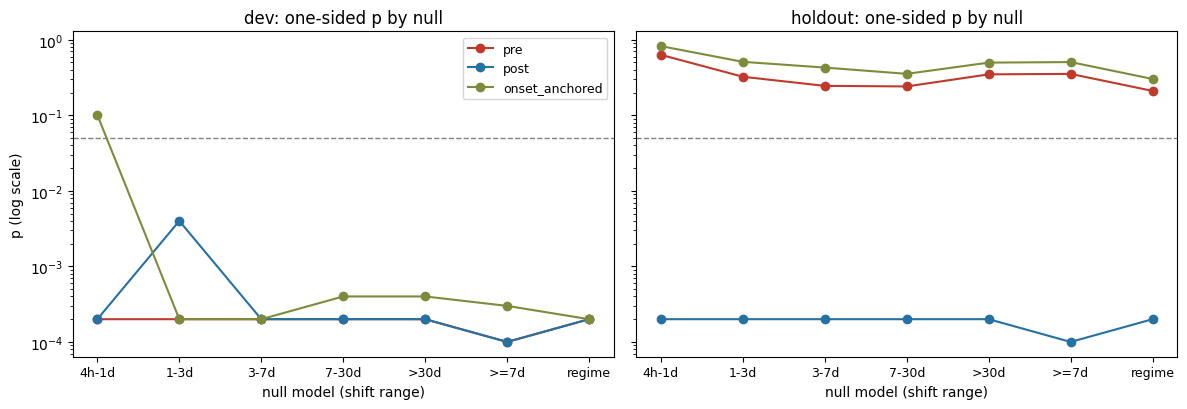

In [9]:
null_order = [f'circular shift {b[0]}' for b in BANDS] + ['circular shift >=7d (primary, section 2)', f'regime-matched (same RV decile, +-{REGIME_WINDOW_D}d)']
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for i, k in enumerate(PERIODS):
    for key, col in [('pre', '#c0392b'), ('post', '#2471a3'), ('onset_anchored', '#7d8c3a')]:
        sub = T3[(T3.period == k) & (T3.endpoint == key)].set_index('null').reindex(null_order)
        ax[i].plot(range(len(null_order)), sub.p_one_sided.to_numpy(), 'o-', color=col, label=key)
    ax[i].axhline(ALPHA, color='grey', ls='--', lw=1); ax[i].set_yscale('log')
    ax[i].set_xticks(range(len(null_order))); ax[i].set_xticklabels(['4h-1d', '1-3d', '3-7d', '7-30d', '>30d', '>=7d', 'regime'], fontsize=9)
    ax[i].set_title(f'{k}: one-sided p by null'); ax[i].set_xlabel('null model (shift range)')
ax[0].set_ylabel('p (log scale)'); ax[0].legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT / '3_null_audit_profile.png', dpi=140); plt.show()

### 3d. Autocorrelation: inter-alert gap structure and event clusters

In [10]:
rows = []
for k in PERIODS:
    g_real = np.diff(ALERTS[k]) / NS; g_reg = REG_GAPS[k]
    rows.append(dict(period=k, events=len(EVENTS[k]), episodes=int(EVENTS[k].episode.nunique()),
                     events_per_episode=len(EVENTS[k]) / EVENTS[k].episode.nunique(),
                     alert_gap_median_real_min=float(np.median(g_real)), alert_gap_median_regime_null_min=float(np.median(g_reg)),
                     share_gaps_below_cooldown_real=float((g_real < COOLDOWN).mean()),
                     share_gaps_below_cooldown_regime_null=float((g_reg < COOLDOWN).mean()),
                     note='circular shift preserves all inter-alert gaps (except one wrap); the regime-matched null does not'))
T3d = pd.DataFrame(rows); T3d.to_csv(OUT / '3d_autocorrelation.csv', index=False); display(T3d.T)

,0,1
period,dev,holdout
events,83,199
episodes,55,80
events_per_episode,1.509091,2.4875
alert_gap_median_real_min,677.0,673.0
alert_gap_median_regime_null_min,1372.0,1401.0
share_gaps_below_cooldown_real,0.0,0.0
share_gaps_below_cooldown_regime_null,0.126395,0.125358
note,circular shift preserves all inter-alert gaps ...,circular shift preserves all inter-alert gaps ...


## 4. Multi-coin shared budget (notebook 10) at the event-cluster level, pre-onset warning and in-progress detection separately

In [11]:
def daily_sigma_2021(index, close):
    r = pd.Series(np.log(close), index=index).diff()
    d = r.loc['2021'].groupby(r.loc['2021'].index.floor('D')).agg(['std', 'count'])
    return float((d.loc[d['count'] >= 1000, 'std'] * np.sqrt(1440)).median())


coin = {}
sig_btc = daily_sigma_2021(px.index, close_all)
for sym in COINS:
    if sym == 'BTCUSDT':
        coin[sym] = dict(T_CAL=T_all[cal_m], S_CAL=S_all[cal_m], T_EV=T_all[ev_m], S_EV=S_all[ev_m], ref22=np.sort(S_all[cal_m]),
                         EVENTS=EVENTS['dev'])
        continue
    d = pd.read_parquet(MC / 'cache' / f'{sym}_1m.parquet'); d.index = d.index.tz_convert('UTC')
    idx = d.index; close = d.close.to_numpy(float); volume = d.volume.to_numpy(float)
    v = d.z_vol.to_numpy(float); f = d.tsr.to_numpy(float)
    valid = np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v) & np.isfinite(f) & (f >= 0) & (f <= 1)
    E = price_only_catalog(close, volume, idx, decline=0.04 * daily_sigma_2021(idx, close) / sig_btc)
    for c_ in TCOLS:
        E[c_] = pd.to_datetime(E[c_], utc=True)
    Es = load_catalog(MC / f'{sym}_price_only_event_catalog.csv')
    if len(E) != len(Es) or any(not np.array_equal(E[c_].astype('int64').to_numpy(), Es[c_].astype('int64').to_numpy()) for c_ in TCOLS):
        raise RuntimeError(f'GUARD FAIL: {sym} catalog differs from notebook 10')
    T = idx.asi8; y = label_from_catalog(T, E); tr = train_mask(T, valid)
    m_ = new_logit().fit(np.column_stack([v, f])[tr], y[tr])
    S = np.full(len(T), np.nan); S[valid] = m_.predict_proba(np.column_stack([v, f])[valid])[:, 1]
    cal = valid & in_period(T, '2022-01-01', '2023-01-01'); ev = valid & in_period(T, EVAL_START, EVAL_END)
    coin[sym] = dict(T_CAL=T[cal], S_CAL=S[cal], T_EV=T[ev], S_EV=S[ev], ref22=np.sort(S[cal]), EVENTS=events_between(E, EVAL_START, EVAL_END))
    del d, S, y


@njit(cache=False)
def _pooled_core(t, cid, years, months, B_total, cap_month, cooldown_ns, ncoins, coin_cap):
    out = np.empty(len(t), np.int64); k = 0
    last = np.full(ncoins, -(2**62), np.int64); ccount = np.zeros(ncoins, np.int64)
    mcount = 0; ycount = 0; pm = -1; py = -1
    for i in range(len(t)):
        yr = years[i]; mo = months[i]; c = cid[i]; ti = t[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
            for j in range(ncoins):
                ccount[j] = 0
        if ycount >= B_total or mcount >= cap_month:
            continue
        if coin_cap > 0 and ccount[c] >= coin_cap:
            continue
        if ti - last[c] < cooldown_ns:
            continue
        out[k] = i; k += 1; last[c] = ti; ycount += 1; mcount += 1; ccount[c] += 1
    return out[:k].copy()


def pooled_stream(part):
    ts_, cid, u = [], [], []
    for j, sym in enumerate(COINS):
        c = coin[sym]; t = c[f'T_{part}']; s = c[f'S_{part}']
        ts_.append(t); cid.append(np.full(len(t), j, np.int64)); u.append(np.searchsorted(c['ref22'], s, 'right') / len(c['ref22']))
    t = np.concatenate(ts_); cid = np.concatenate(cid); u = np.concatenate(u)
    order = np.lexsort((-u, t)); t, cid, u = t[order], cid[order], u[order]
    yrs, mons = cal_fields(t)
    return t, cid, u, yrs, mons


def run_pool(stream, thr):
    t, cid, u, yrs, mons = stream; sel = u >= thr
    k = _pooled_core(t[sel], cid[sel], yrs[sel], mons[sel], POOL_B, POOL_CAP, np.int64(COOLDOWN * NS), len(COINS), 0)
    tt = t[sel][k]; cc = cid[sel][k]
    return {sym: tt[cc == j] for j, sym in enumerate(COINS)}


POL = {'S0': {}}
for sym, c in coin.items():
    th, _, _ = calibrate_calendar(c['T_CAL'], c['S_CAL'])
    POL['S0'][sym] = emit_calendar_fast(c['T_EV'], c['S_EV'] >= th)
cal_s = pooled_stream('CAL'); ev_s = pooled_stream('EV')
ugrid = np.unique(np.r_[np.quantile(cal_s[2], np.r_[np.linspace(.90, .999, 45), .9995, .9999]), 1.0])
g = pd.DataFrame([(float(u_), sum(len(a) for a in run_pool(cal_s, u_).values()), int((cal_s[2] >= u_).sum())) for u_ in ugrid],
                 columns=['u', 'cal_alerts', 'raw'])
POL['S1'] = run_pool(ev_s, float(g[g.cal_alerts == g.cal_alerts.max()].sort_values('raw').iloc[0].u))
ref10 = pd.read_csv(MC / 'multicoin_policy_by_coin.csv')
for pol, name in [('S0', 'S0_separate'), ('S1', 'S1_pooled')]:
    for sym in COINS:
        s_ = statistics(coin[sym]['EVENTS'], POL[pol][sym]); r = ref10[(ref10.policy == name) & (ref10.coin == sym)].iloc[0]
        if [s_['alarms'], s_['caught'], s_['before_1pct']] != [int(r.alarms), int(r.caught), int(r.before_1pct)]:
            raise RuntimeError(f'GUARD FAIL: {name} {sym} differs from notebook 10')
print('PASS: notebook-10 S0/S1 reproduced for all coins')

PASS: notebook-10 S0/S1 reproduced for all coins


In [12]:
ALLEV = pd.concat([coin[s]['EVENTS'][['event_id'] + TCOLS].assign(coin=s) for s in COINS], ignore_index=True)
for pol in ['S0', 'S1']:
    hit = np.zeros(len(ALLEV), bool); pre = np.zeros(len(ALLEV), bool)
    for s in COINS:
        mk = (ALLEV.coin == s).to_numpy(); m = match_events(coin[s]['EVENTS'], POL[pol][s])
        hit[mk] = coin[s]['EVENTS'].event_id.isin(set(m.event_id)).to_numpy()
        pre[mk] = coin[s]['EVENTS'].event_id.isin(set(m.loc[m.pre1pct, 'event_id'])).to_numpy()
    ALLEV[f'caught_{pol}'] = hit; ALLEV[f'pre_{pol}'] = pre; ALLEV[f'post_{pol}'] = hit & ~pre
bt = ALLEV.breach_utc.astype('int64').to_numpy(); order = np.argsort(bt, kind='stable')
ALLEV['shock'] = 0; ALLEV.loc[order, 'shock'] = np.r_[0, np.cumsum(np.diff(bt[order]) > SHOCK_GAP_MIN * NS)]
ALLEV['month'] = ALLEV.breach_utc.dt.strftime('%Y-%m')
sh = ALLEV.groupby('shock').agg(n_events=('coin', 'size'), n_coins=('coin', 'nunique'))
print(f'{len(ALLEV)} coin-events -> {len(sh)} shocks ({int((sh.n_coins >= 2).sum())} multi-coin); months {ALLEV.month.nunique()}')


def signflip(d, groups, n=N_FLIPS, seed=SEED):
    G_ = pd.Series(d.astype(float)).groupby(np.asarray(groups)).sum().to_numpy()
    obs = float(G_.sum()); nz = G_[G_ != 0]; rng = np.random.default_rng(seed); cnt = 0; done = 0
    while done < n:
        k_ = min(20000, n - done)
        s_ = rng.integers(0, 2, size=(k_, len(nz))) * 2.0 - 1.0
        cnt += int((np.abs(s_ @ nz) >= abs(obs) - 1e-9).sum()); done += k_
    return obs, len(G_), len(nz), (1 + cnt) / (n + 1)


rows = []
for metric, cls in [('pre', 'early warning'), ('post', 'in-progress detection'), ('caught', 'composite (reference)')]:
    a = ALLEV[f'{metric}_S0'].to_numpy(); b = ALLEV[f'{metric}_S1'].to_numpy(); dlt = b.astype(int) - a.astype(int)
    ex = mcnemar_two_sided(int((a & ~b).sum()), int((b & ~a).sum()))
    for level, groups in [('event', np.arange(len(ALLEV))), ('shock', ALLEV.shock.to_numpy()), ('month', ALLEV.month.to_numpy())]:
        obs, ng, nnz, p = signflip(dlt, groups)
        rows.append(dict(endpoint=metric, endpoint_class=cls, cluster=level, separate=int(a.sum()), pooled=int(b.sum()), difference=int(obs),
                         clusters=ng, clusters_with_difference=nnz, p_two_sided=p, exact_mcnemar_event=ex))
T4 = pd.DataFrame(rows)
evr = T4[T4.cluster == 'event']
if (np.abs(evr.p_two_sided - evr.exact_mcnemar_event) > 0.01 + 0.5 * evr.exact_mcnemar_event).any():
    raise AssertionError('event-level sign-flip p does not match exact McNemar')
T4.to_csv(OUT / '4_pooling_by_endpoint_and_cluster.csv', index=False); ALLEV.to_csv(OUT / '4_coin_events_flags.csv', index=False)
print('PASS: event-level sign-flip agrees with exact McNemar'); display(T4.round(5))

397 coin-events -> 204 shocks (97 multi-coin); months 39
PASS: event-level sign-flip agrees with exact McNemar


,endpoint,endpoint_class,cluster,separate,pooled,difference,clusters,clusters_with_difference,p_two_sided,exact_mcnemar_event
0,pre,early warning,event,61,66,5,397,39,0.52344,0.52240
1,pre,early warning,shock,61,66,5,204,29,0.50343,0.52240
2,pre,early warning,month,61,66,5,39,14,0.50100,0.52240
3,post,in-progress detection,event,103,129,26,397,60,0.00093,0.00107
4,post,in-progress detection,shock,103,129,26,204,49,0.00125,0.00107
5,post,in-progress detection,month,103,129,26,39,22,0.00354,0.00107
6,caught,composite (reference),event,164,195,31,397,69,0.00025,0.00024
7,caught,composite (reference),shock,164,195,31,204,55,0.00048,0.00024
8,caught,composite (reference),month,164,195,31,39,24,0.00058,0.00024


## Summary

In [13]:
def p_of(df, **kw):
    r = df
    for c_, v_ in kw.items():
        r = r[r[c_] == v_]
    return float(r.p_one_sided.iloc[0]) if 'p_one_sided' in r else float(r.p_two_sided.iloc[0])


band_short = f'circular shift {BANDS[0][0]}'; reg_name = f'regime-matched (same RV decile, +-{REGIME_WINDOW_D}d)'
summary = {'spec_sha256': SPEC_SHA, 'periods': PERIODS, 'endpoint_table': T1.to_dict('records')}
for k in PERIODS:
    summary[k] = {}
    for key in ['pre', 'post', 'onset_anchored', 'episodes_pre', 'episodes_caught']:
        p_main = p_of(T2, period=k, endpoint=key)
        p_short = p_of(T3, period=k, endpoint=key, null=band_short)
        p_reg = p_of(T3, period=k, endpoint=key, null=reg_name)
        summary[k][key] = dict(observed=OBS[k][key], p_primary=p_main, p_4h_1d=p_short, p_regime_matched=p_reg,
                               reading=('no skill under the primary null' if p_main >= ALPHA else
                                        ('timing-specific skill' if (p_short < ALPHA and p_reg < ALPHA) else 'regime-level skill only')))
summary['pooling'] = {f'{r.endpoint}/{r.cluster}': dict(difference=r.difference, p=r.p_two_sided) for r in T4.itertuples()}
(OUT / 'RELIABILITY_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
for k in PERIODS:
    print(k, {key: (v['observed'], round(v['p_primary'], 4), v['reading']) for key, v in summary[k].items()})
print('pooling:', {key: (v['difference'], round(v['p'], 4)) for key, v in summary['pooling'].items()})

dev {'pre': (22, 0.0001, 'timing-specific skill'), 'post': (17, 0.0001, 'timing-specific skill'), 'onset_anchored': (29, 0.0003, 'regime-level skill only'), 'episodes_pre': (16, 0.0001, 'timing-specific skill'), 'episodes_caught': (27, 0.0001, 'timing-specific skill')}
holdout {'pre': (13, 0.3532, 'no skill under the primary null'), 'post': (23, 0.0001, 'timing-specific skill'), 'onset_anchored': (22, 0.5063, 'no skill under the primary null'), 'episodes_pre': (10, 0.4244, 'no skill under the primary null'), 'episodes_caught': (28, 0.0001, 'timing-specific skill')}
pooling: {'pre/event': (5, 0.5234), 'pre/shock': (5, 0.5034), 'pre/month': (5, 0.501), 'post/event': (26, 0.0009), 'post/shock': (26, 0.0012), 'post/month': (26, 0.0035), 'caught/event': (31, 0.0002), 'caught/shock': (31, 0.0005), 'caught/month': (31, 0.0006)}
